# Отчёт по лабораторной работе №3

## Spring Security

**Дисциплина:** Разработка кроссплатформенных приложений, семестр 2

**Выполнил:** студент группы 12002408

Блинов Кирилл Игоревич

**Проверил:** ассистент кафедры информационных и робототехнических систем

Пузырев Никита Сергеевич

<br>
<br>

**Сайт курсового проекта:** [https://hki-stroitel.ru/](https://hki-stroitel.ru/)


<p align="justify"><strong>Цель работы:</strong> изучить аутентификацию, управление сеансами и разграничение доступа с помощью Spring Security на примере приложения расписания.</p>

<h2 align="center">Задание</h2>

1. Изучить теоретический материал по Spring Security.
2. Написать приложение, следуя примеру из методических указаний.
3. Выполнить дополнительное задание: добавить ещё одну или две роли для функционала предыдущей лабораторной работы.
4. Оформить отчёт.

В работе пример адаптирован к готовому приложению расписания: настроены вход, выход, хранение паролей, сессия и ограничения доступа. Дополнительно введены роли студента и методиста.


## Ход работы

### 1. Основа приложения

Третья работа продолжает приложение расписания `raspisa-hki`. В этой копии подключена зависимость `spring-boot-starter-security`. Она добавляет фильтры безопасности и средства авторизации. Точка входа по-прежнему находится в `RaspisaApplication`.

Лабораторная запускается на этом ПК. Для данных используется отдельная файловая база H2 `data/raspisa-lab3`. PostgreSQL для такого запуска устанавливать не требуется. Изменения лабораторной подготовлены локально; опубликованный сайт курсовой автоматически ими не обновляется.

Блокнот содержит пояснения и небольшие примеры Java-кода в текстовых ячейках. Исполняемых ячеек, установки зависимостей и запуска приложения в Google Colab нет.


### 2. Роли пользователей

В существующий `enum Role` добавлены роли `STUDENT` и `METHODIST`. У каждого пользователя одна роль, которая хранится в базе данных.

Файл: `src/main/java/ru/raspisa/entity/Role.java`.


```java
package ru.raspisa.entity;

public enum Role {
    ADMIN,
    TEACHER,
    STUDENT,
    METHODIST
}
```


| Роль | Возможности в панели |
| --- | --- |
| `ADMIN` | Все разделы: журнал, расписание, мероприятия, праздники, каникулы и студии |
| `TEACHER` | Только журнал посещаемости |
| `STUDENT` | Просмотр мероприятий |
| `METHODIST` | Просмотр, добавление, изменение и удаление мероприятий |

Общедоступные страницы курсового сайта остаются доступными для просмотра. Таблица описывает права в панели; изменение данных дополнительно контролируется сервером.


### 3. Хранение паролей

В `SecurityConfig` создан `PasswordEncoder`, использующий BCrypt. В базе хранится хеш пароля, а введённый пароль сопоставляется с ним при аутентификации.

Файл: `src/main/java/ru/raspisa/config/SecurityConfig.java`.


```java
@Bean
public PasswordEncoder passwordEncoder() {
    return new BCryptPasswordEncoder();
}
```


### 4. Получение пользователя для Spring Security

`UserDetailsService` получает пользователя из `UserRepository`, передаёт Spring Security его логин, хеш пароля и роль. Если логин не найден, выбрасывается `UsernameNotFoundException`.


```java
@Bean
public UserDetailsService userDetailsService(UserRepository users) {
    return login -> {
        var user = users.findByLogin(login);
        if (user == null) throw new UsernameNotFoundException("Пользователь не найден");
        return org.springframework.security.core.userdetails.User.withUsername(user.getLogin())
                .password(user.getPasswordHash()).roles(user.getRole().name()).build();
    };
}
```


### 5. Вход пользователя

Метод `AuthService.login` передаёт логин и пароль в `AuthenticationManager`. Если аутентификация не прошла, возвращается ошибка входа. При успехе формируется `UserDto` с логином, ролью и именем; хеш пароля в ответ не включается.

Файл: `src/main/java/ru/raspisa/service/AuthService.java`.


```java
@Transactional(readOnly = true)
public UserDto login(String login, String rawPassword) {
    try {
        authenticationManager.authenticate(UsernamePasswordAuthenticationToken.unauthenticated(login, rawPassword));
    } catch (AuthenticationException exception) {
        throw new InvalidCredentialsException("Неверный логин или пароль");
    }
    User user = userRepository.findByLogin(login);
    return new UserDto(user.getLogin(), user.getRole().name(), user.getFullName());
}
```


### 6. Сохранение входа в сессии

После входа `SecuritySessionService` создаёт контекст безопасности с ролью пользователя и сохраняет его через `SecurityContextRepository`. Поэтому следующие запросы с той же сессией выполняются от имени вошедшего пользователя. Идентификатор сессии при входе меняется.

Фрагмент из `src/main/java/ru/raspisa/service/SecuritySessionService.java`.


```java
public void login(UserDto user, HttpServletRequest request, HttpServletResponse response) {
    var session = request.getSession();
    request.changeSessionId();
    var authentication = UsernamePasswordAuthenticationToken.authenticated(user.login(), null,
            List.of(new SimpleGrantedAuthority("ROLE_" + user.role())));
    var context = SecurityContextHolder.createEmptyContext();
    context.setAuthentication(authentication);
    SecurityContextHolder.setContext(context);
    session.setAttribute("schoolUser", user);
    session.setAttribute("schoolStaff", List.of("ADMIN", "TEACHER").contains(user.role()));
    session.setAttribute("map-admin", "ADMIN".equals(user.role()));
    tokens.saveToken(null, request, response);
    contexts.saveContext(context, request, response);
}
```


### 7. Настройка доступа

В `SecurityConfig` объявлен `SecurityFilterChain`. Он пропускает общедоступные запросы, требует вход для панели и задаёт допустимые роли для API.

Журнал доступен только `ADMIN` и `TEACHER`. Изменение групп, студий, праздников и обычного расписания разрешено администратору. Запросы изменения мероприятий допускают администратора и методиста, после чего выполняется дополнительное ограничение на конкретную запись.

В `LessonController` используется `@PreAuthorize`. Для добавления вызывается правило `eventAccess.canCreate`, для изменения – `canUpdate`, для удаления – `canDelete`.

Пример метода изменения занятия:


```java
@PreAuthorize("@eventAccess.canUpdate(#id, #request)")
@PutMapping("/{id}")
public LessonDto update(@PathVariable Long id, @Valid @RequestBody LessonRequest request) {
    return lessonService.update(id, request);
}
```


### 8. Методист управляет только мероприятиями

Мероприятие в проекте хранится как `Lesson` с признаком `special = true`. Правила класса `EventAccess` позволяют методисту создавать только такие записи. Для изменения учитывается и прежняя запись в базе, и новые данные запроса.

Поэтому методист не может изменить обычное занятие, превратить его в мероприятие или превратить мероприятие в обычное занятие. Администратор имеет доступ к обоим типам записей.

Файл: `src/main/java/ru/raspisa/config/EventAccess.java`.


```java
public boolean canUpdate(Long id, LessonRequest request) {
    return hasRole("ADMIN") || hasRole("METHODIST") && Boolean.TRUE.equals(request.special())
            && lessons.findById(id).map(Lesson::isSpecial).orElse(false);
}
```


Метод удаления разрешает методисту удалять только существующие мероприятия.


```java
public boolean canDelete(Long id) {
    return hasRole("ADMIN") || hasRole("METHODIST")
            && lessons.findById(id).map(Lesson::isSpecial).orElse(false);
}
```


### 9. Защита запросов и выход

Для POST-, PUT- и DELETE-запросов используется CSRF-токен. Интерфейс получает его через `/api/auth/csrf` и передаёт в заголовке запроса. Это дополняет проверку сессии и роли.

В `AuthController` токен выдаётся отдельным GET-методом:


```java
@GetMapping("/csrf")
public ResponseEntity<Map<String, String>> csrf(CsrfToken token) {
    return ResponseEntity.ok().cacheControl(CacheControl.noStore())
            .body(Map.of("headerName", token.getHeaderName(), "token", token.getToken()));
}
```


При выходе удаляется токен, завершается сессия и очищается контекст безопасности.


```java
public void logout(HttpServletRequest request, HttpServletResponse response) {
    tokens.saveToken(null, request, response);
    var session = request.getSession(false);
    if (session != null) session.invalidate();
    SecurityContextHolder.clearContext();
}
```


### 10. Панель пользователя

Страница `DashboardPage.jsx` получает текущего пользователя с сервера через `/api/auth/me` и показывает доступные разделы.

Администратор видит всю панель. Преподавателю показывается журнал. Студенту показываются мероприятия без кнопок редактирования. Методисту доступен редактор только мероприятий; кнопки добавления праздников и каникул скрыты.

Проверки на сервере работают независимо от видимости кнопок. При отсутствии входа защищённый API возвращает `401`, при недостаточных правах – `403`.


### 11. Запуск на ПК и учебные учётные записи

В папке проекта подготовлен файл `start-lab3.bat`. Он запускает готовый JAR из `build/libs/raspisa-lab3.jar`. Если JAR отсутствует, сначала выполняется сборка Gradle. Для готового JAR нужна Java 17; для повторной сборки интерфейса также нужен Node.js.

Учётные записи создаются при первом запуске локальной базы:

| Логин | Учебный пароль | Роль |
| --- | --- | --- |
| `admin` | `Admin!2026` | Администратор |
| `teacher` | `Teacher!2026` | Преподаватель |
| `student` | `Student!2026` | Студент |
| `methodist` | `Methodist!2026` | Методист |

Чтобы сменить пользователя, нужно выйти из текущей учётной записи и войти под другим логином. Параметры `LAB_ADMIN_PASSWORD`, `LAB_TEACHER_PASSWORD`, `LAB_STUDENT_PASSWORD` и `LAB_METHODIST_PASSWORD` позволяют задать другие начальные пароли до создания базы.


### 12. Результат работы приложения

Скриншоты сняты при запуске лабораторной на этом ПК. Для каждой роли выполнен отдельный вход. В локальной базе на момент съёмки нет учеников в выбранной группе и ближайших мероприятий, поэтому эти разделы показывают пустое состояние.


**Форма входа**

Пользователь вводит логин и пароль. Проверку учётных данных выполняет Spring Security на сервере.

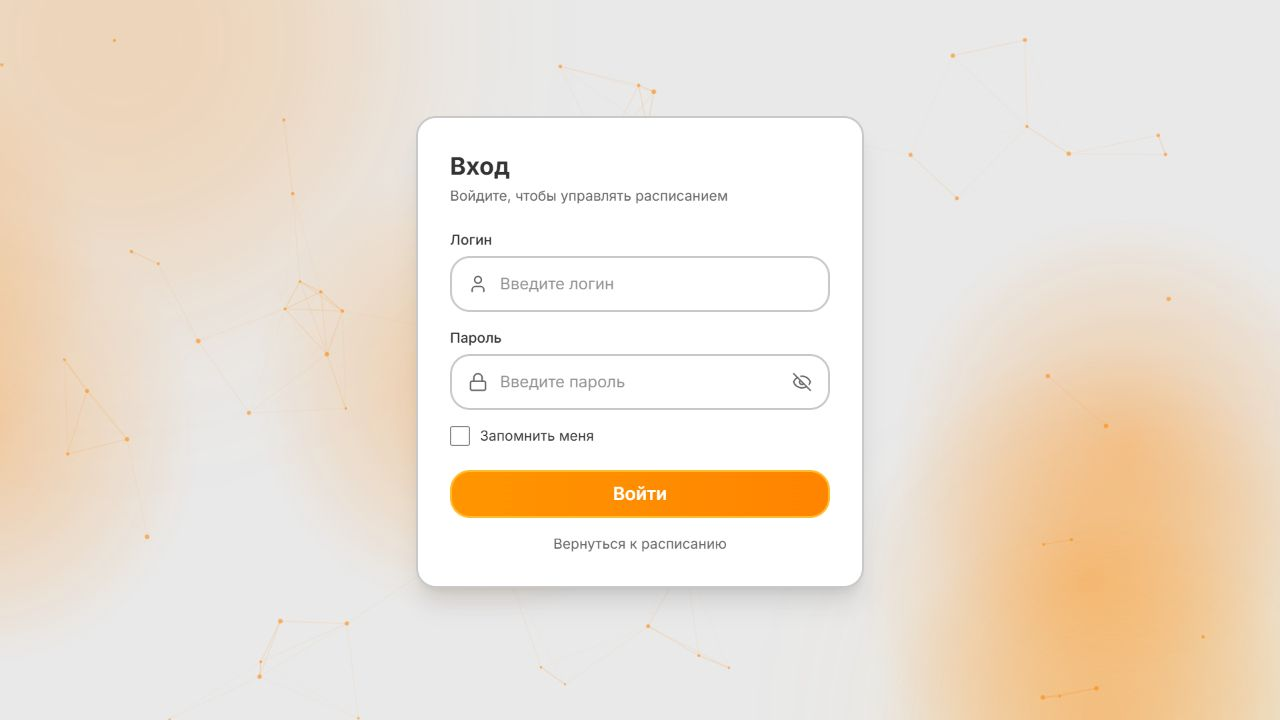

*Рисунок 1 – Форма входа*


**Панель администратора**

Администратору доступны посещаемость, общее расписание, мероприятия, праздники, каникулы и редактирование студий. На снимке часть разделов свёрнута.

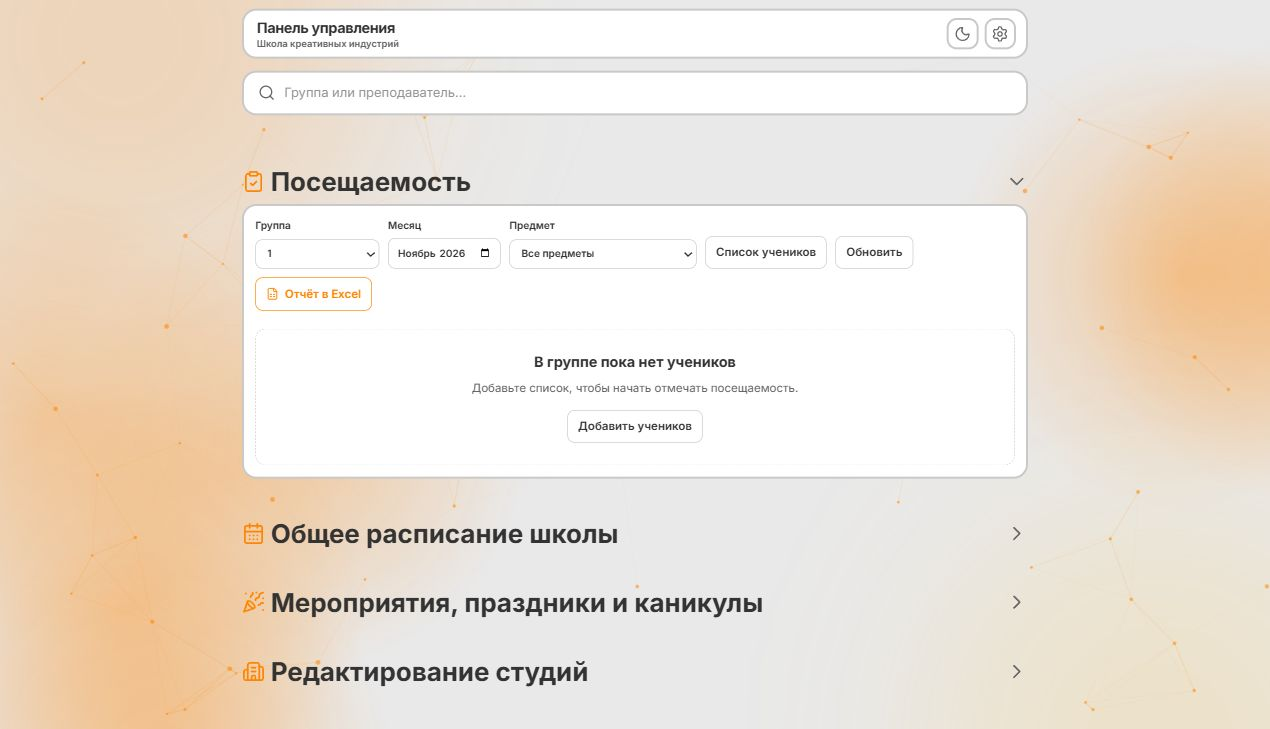

*Рисунок 2 – Панель администратора*


**Журнал преподавателя**

Преподаватель видит только журнал посещаемости. В нём доступны выбор группы, месяца и предмета, работа со списком учеников и отчёт в Excel.

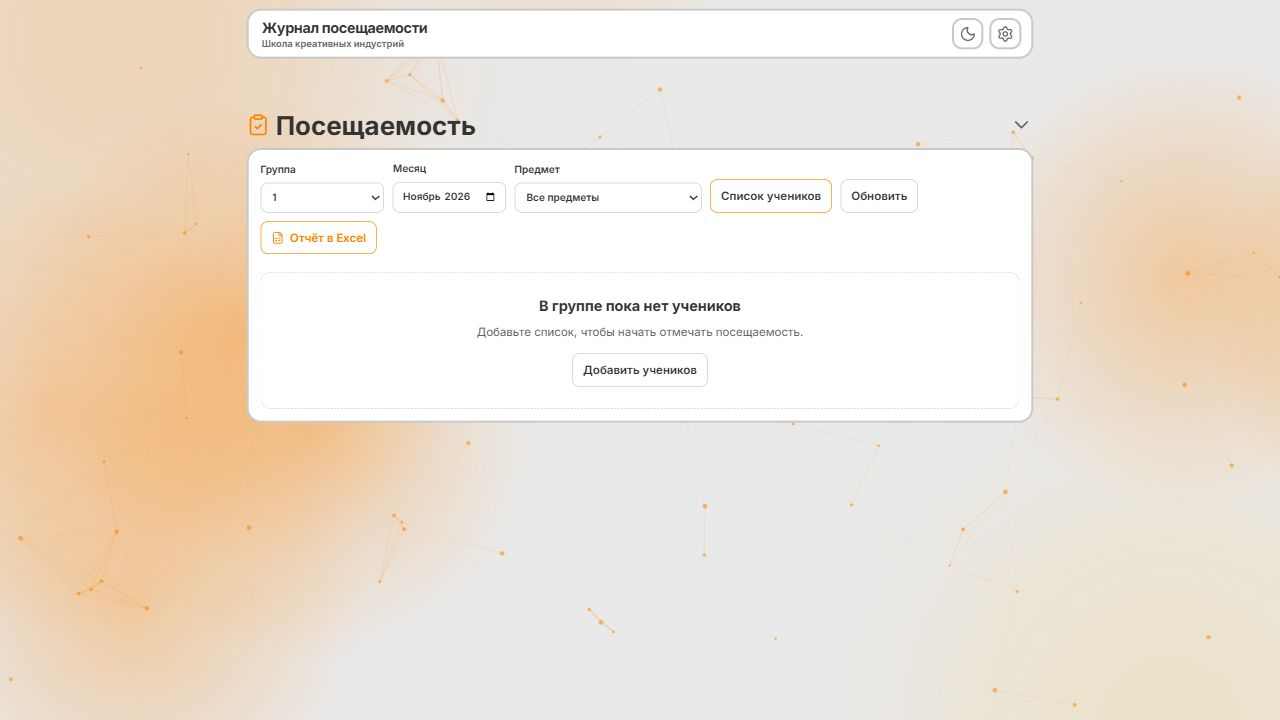

*Рисунок 3 – Журнал преподавателя*


**Просмотр мероприятий студентом**

Студенту доступен просмотр мероприятий без управления расписанием и журналом. На снимке отображается сообщение об отсутствии ближайших мероприятий.

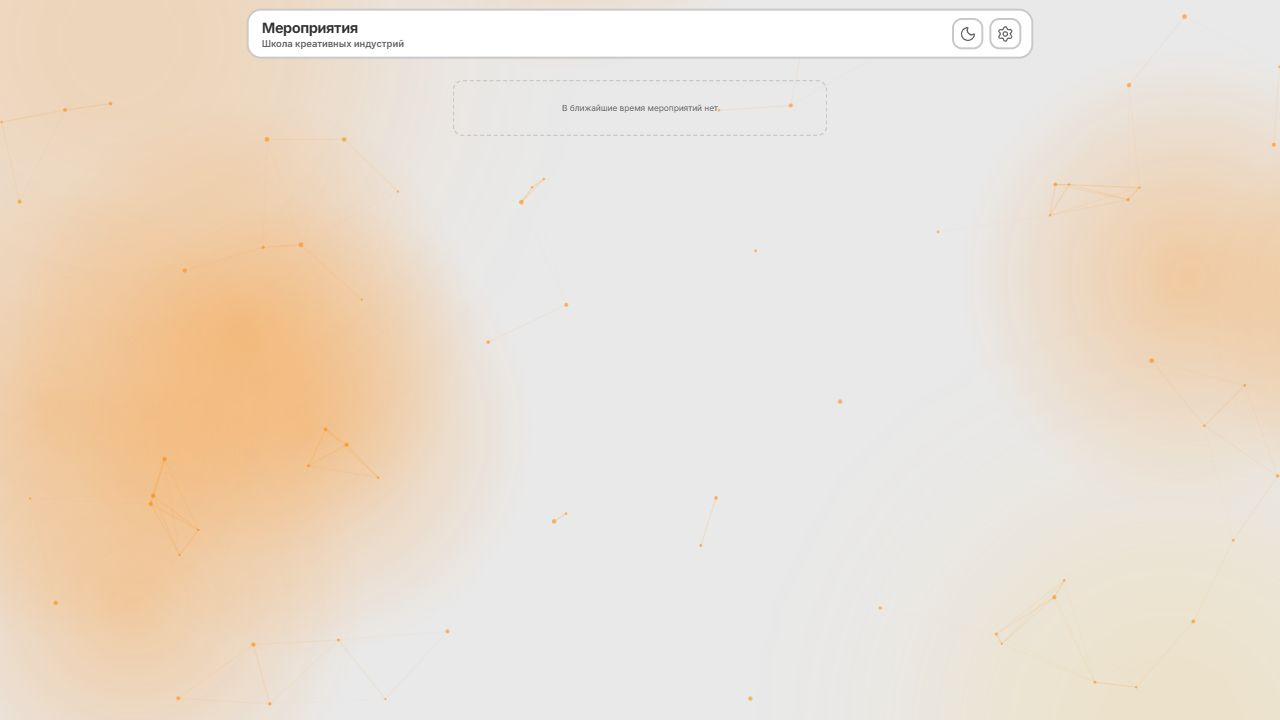

*Рисунок 4 – Просмотр мероприятий студентом*


**Панель методиста**

Методист видит раздел мероприятий и кнопку добавления. Разделы журнала, обычного расписания, студий, праздников и каникул ему не доступны.

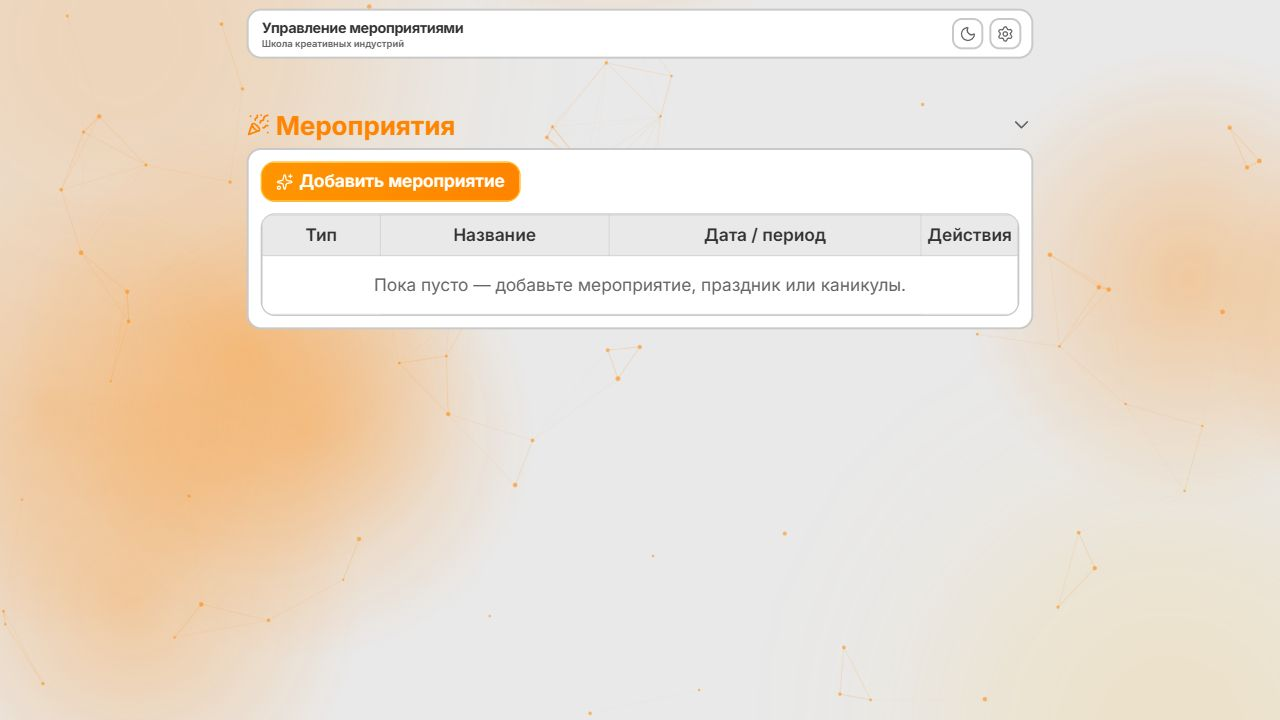

*Рисунок 5 – Панель методиста*


## Вывод

Изучил аутентификацию, управление сессией и разграничение доступа в Spring Security, настроив четыре роли в локальном приложении расписания.
